Loading snapshots ...
Done.
sigma_vm max: 1600 MPa


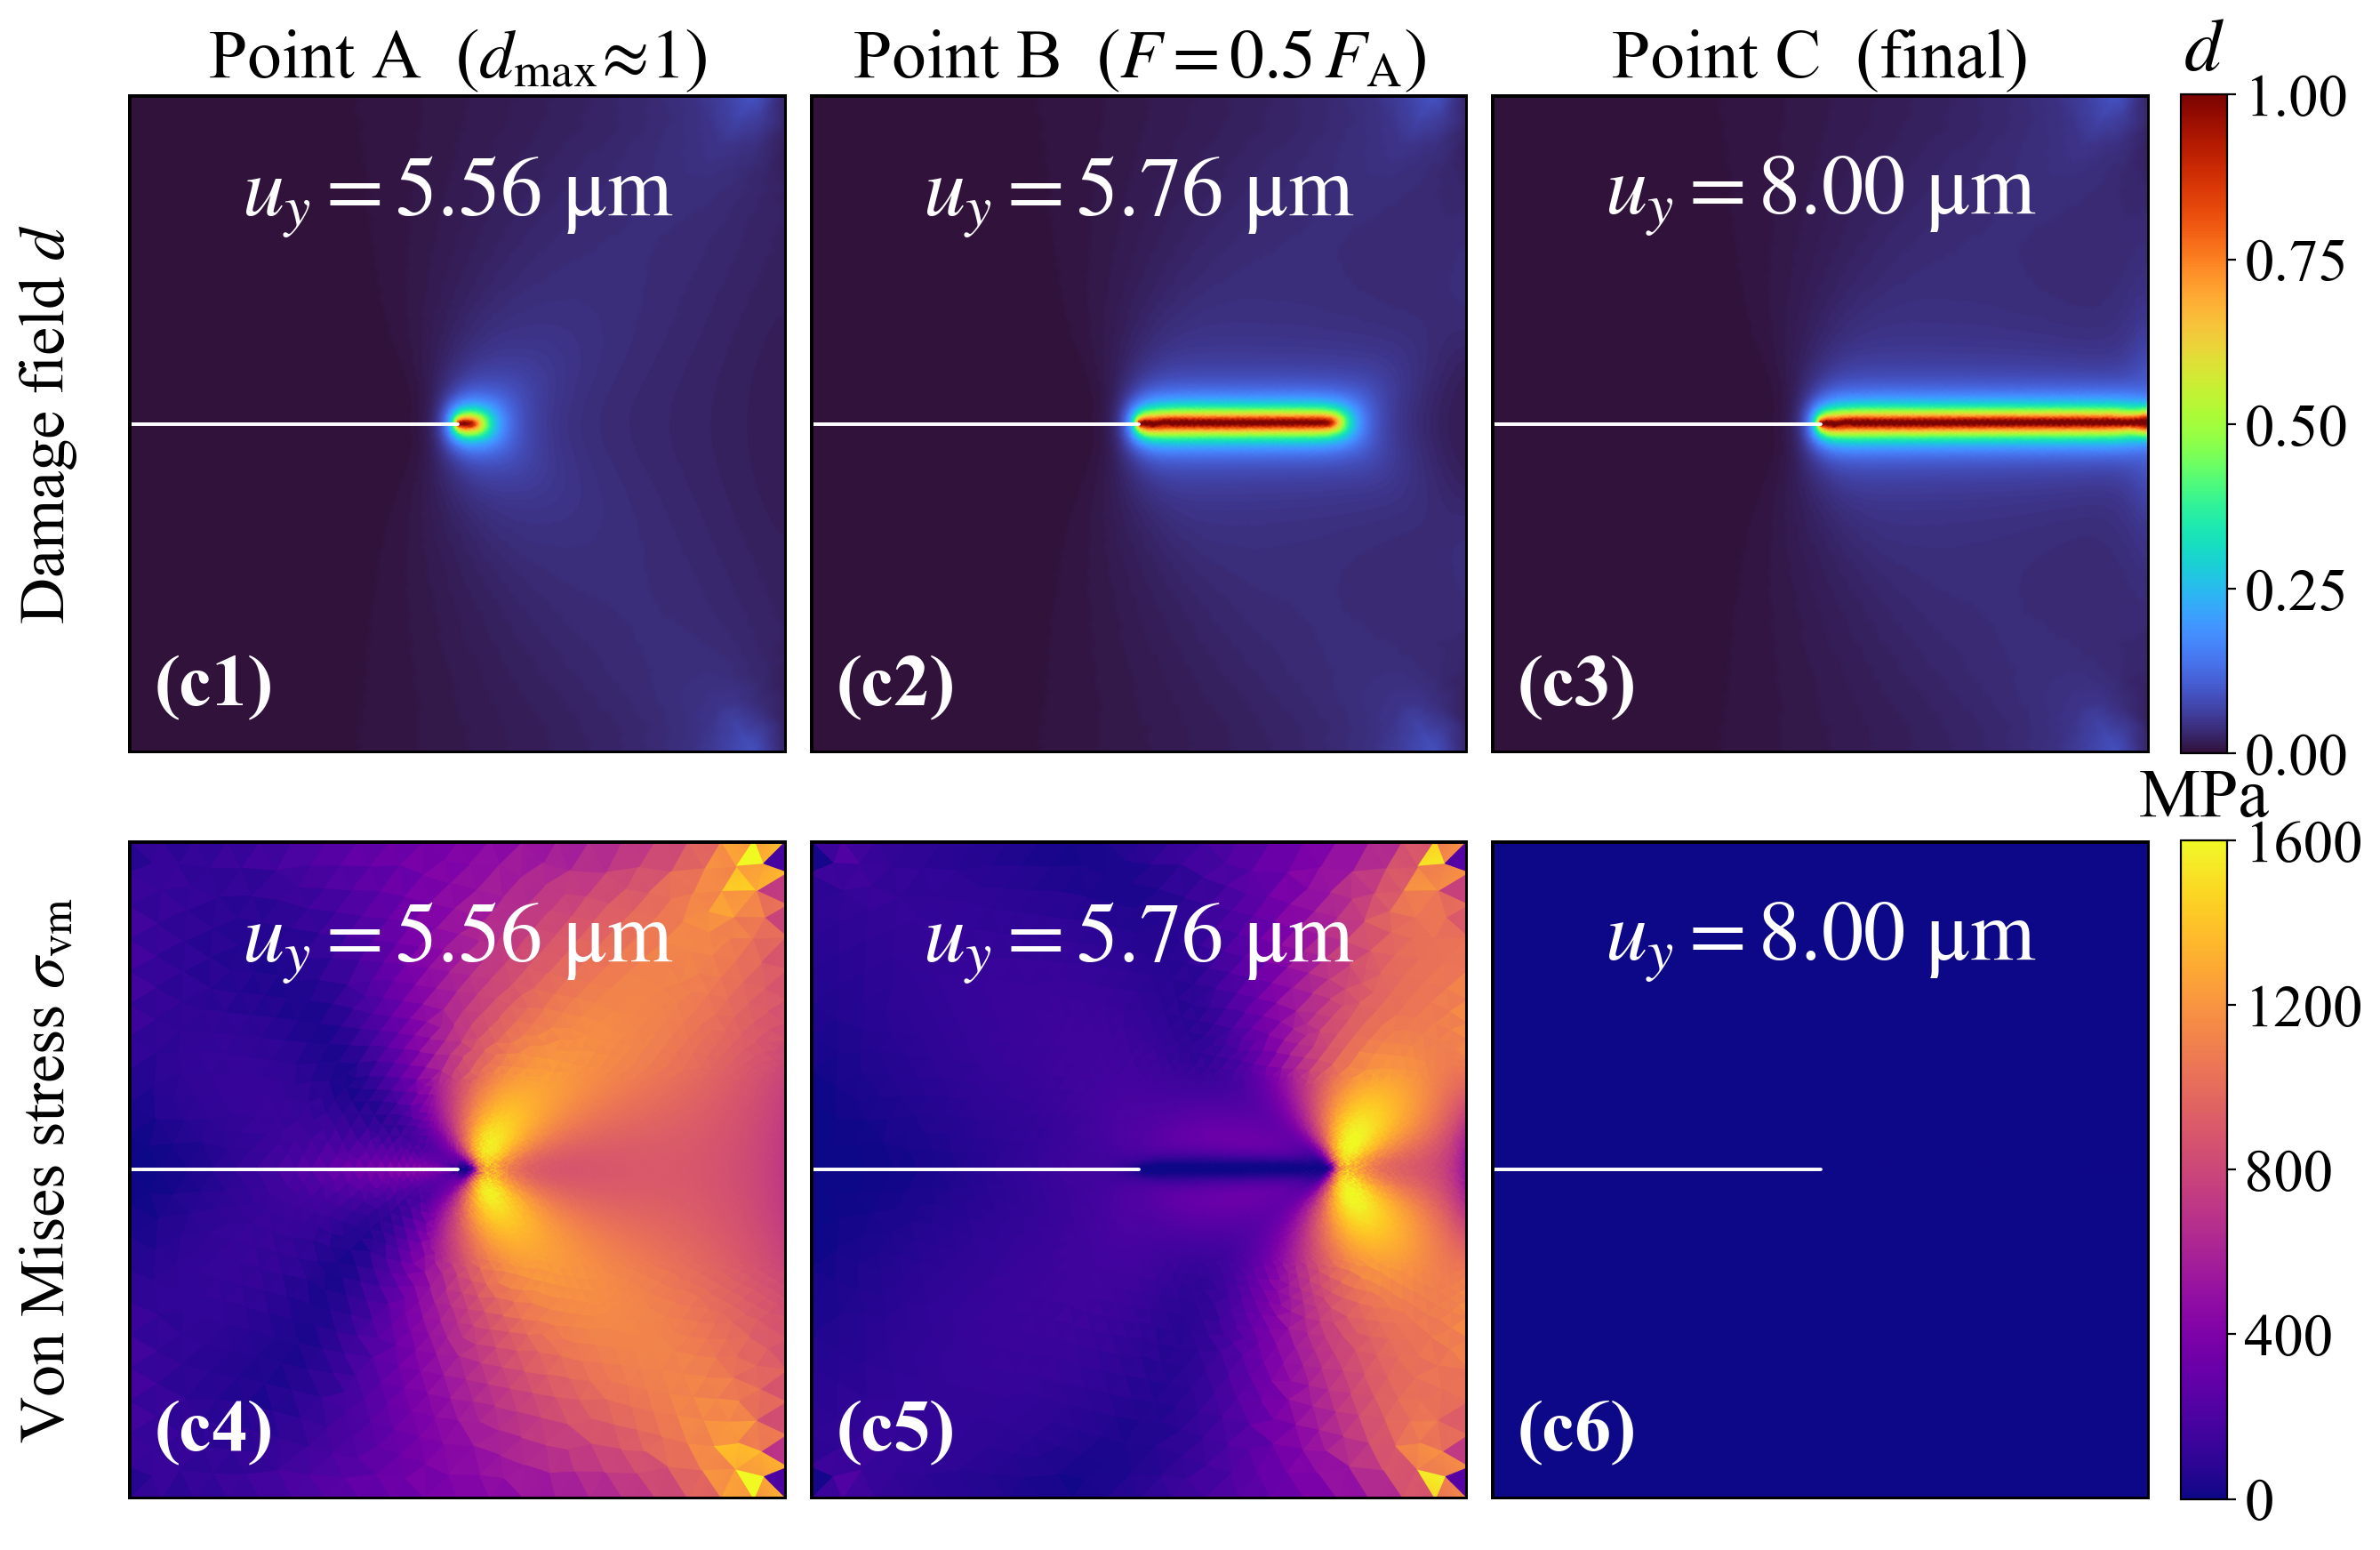

In [3]:
from pathlib import Path
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
import meshio

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        28,
    'figure.dpi':       200,
})
BORDER_LW = 2.5

RESULTS = Path('results_SENT_tension')
FILES = [
    RESULTS / 'result_onset_step0664.vtu',
    RESULTS / 'result_drop50_step0697.vtu',
    RESULTS / 'result_final.vtu',
]
LAM = 121_150.0
G   =  80_770.0

def load_snap(path):
    mesh  = meshio.read(path)
    pts   = mesh.points[:, :2]
    cells = next(cb.data for cb in mesh.cells if cb.type == 'triangle')
    d     = mesh.point_data['d'].ravel()
    uh    = mesh.point_data['uh'][:, :2]

    p1, p2, p3 = pts[cells[:,0]], pts[cells[:,1]], pts[cells[:,2]]
    u1, u2, u3 = uh[cells[:,0]],  uh[cells[:,1]],  uh[cells[:,2]]
    twoA = ((p2[:,0]-p1[:,0])*(p3[:,1]-p1[:,1])
           -(p3[:,0]-p1[:,0])*(p2[:,1]-p1[:,1]))

    dN1dx=(p2[:,1]-p3[:,1])/twoA; dN1dy=(p3[:,0]-p2[:,0])/twoA
    dN2dx=(p3[:,1]-p1[:,1])/twoA; dN2dy=(p1[:,0]-p3[:,0])/twoA
    dN3dx=(p1[:,1]-p2[:,1])/twoA; dN3dy=(p2[:,0]-p1[:,0])/twoA

    exx = u1[:,0]*dN1dx + u2[:,0]*dN2dx + u3[:,0]*dN3dx
    eyy = u1[:,1]*dN1dy + u2[:,1]*dN2dy + u3[:,1]*dN3dy
    exy = 0.5*(u1[:,0]*dN1dy+u2[:,0]*dN2dy+u3[:,0]*dN3dy
              +u1[:,1]*dN1dx+u2[:,1]*dN2dx+u3[:,1]*dN3dx)

    trE = exx + eyy
    sxx = LAM*trE + 2*G*exx
    syy = LAM*trE + 2*G*eyy
    szz = LAM*trE
    sxy = 2*G*exy
    svm_e = np.sqrt(0.5*((sxx-syy)**2+(syy-szz)**2+(szz-sxx)**2)+3*sxy**2)

    d_e = (d[cells[:,0]]+d[cells[:,1]]+d[cells[:,2]])/3.0
    g_e = np.clip((1.0-d_e)**2, 0.0, 1.0)
    sv  = np.clip(g_e*svm_e, 0.0, 1e8)

    area  = np.abs(twoA)*0.5
    w_num = np.zeros(len(pts)); a_den = np.zeros(len(pts))
    for k in range(3):
        np.add.at(w_num, cells[:,k], sv*area)
        np.add.at(a_den, cells[:,k], area)
    svm_n = w_num / np.maximum(a_den, 1e-30)

    return {
        'tri':  mtri.Triangulation(pts[:,0], pts[:,1], triangles=cells),
        'd':    d,
        'svm':  svm_n,
        'u_um': float(np.nanmax(uh[:,1])*1e3),
    }

print('Loading snapshots ...')
snaps = [load_snap(f) for f in FILES]
print('Done.')

CMAP_D = plt.get_cmap('turbo')
CMAP_S = plt.get_cmap('plasma')
D_NORM = mpl.colors.Normalize(0.0, 1.0)
all_svm = np.concatenate([s['svm'] for s in snaps])
S_MAX   = np.ceil(np.percentile(all_svm[all_svm > 10.0], 98) / 200) * 200
S_NORM  = mpl.colors.Normalize(0.0, S_MAX)
print(f'sigma_vm max: {S_MAX:.0f} MPa')

PANEL_LBL = [['(c1)','(c2)','(c3)'],
             ['(c4)','(c5)','(c6)']]
COL_HDRS  = [
    r'Point A  ($d_{\max}\!\approx\!1$)',
    r'Point B  ($F=0.5\,F_\mathrm{A}$)',
    r'Point C  (final)',
]
ROW_LBLS  = [
    r'Damage field $d$',
    r'Von Mises stress $\sigma_\mathrm{vm}$',
]

fig = plt.figure(figsize=(14.5, 9.2))
gs  = GridSpec(2, 3, figure=fig,
               hspace=0.10, wspace=0.035,
               left=0.096, right=0.88, top=0.91, bottom=0.04)
ax_grid = [[fig.add_subplot(gs[r,c]) for c in range(3)] for r in range(2)]

for row in range(2):
    for col in range(3):
        ax   = ax_grid[row][col]
        snap = snaps[col]
        fld  = snap['d'] if row == 0 else snap['svm']
        cmap = CMAP_D    if row == 0 else CMAP_S
        norm = D_NORM    if row == 0 else S_NORM
        ax.tripcolor(snap['tri'], fld, cmap=cmap, norm=norm,
                     shading='gouraud', rasterized=True)

        ax.plot([0.0,0.5],[0.5,0.5], color='white', lw=1.4, solid_capstyle='round')
        ax.set_xlim(0.0,1.0); ax.set_ylim(0.0,1.0)
        ax.set_aspect('equal'); ax.axis('off')
        ax.add_patch(Rectangle((0,0),1,1, transform=ax.transAxes, fill=False,
                                edgecolor='black', lw=BORDER_LW, zorder=20))

        ax.text(0.04, 0.05, PANEL_LBL[row][col],
                transform=ax.transAxes,
                fontsize=30, fontweight='bold', color='white',
                va='bottom', ha='left', zorder=25)

        ax.text(0.50, 0.91,
                rf'$u_y={snap["u_um"]:.2f}\ \mathrm{{\mu m}}$',
                transform=ax.transAxes,
                fontsize=34, color='white',
                ha='center', va='top', zorder=25)

        if row == 0:
            ax.set_title(COL_HDRS[col], fontsize=28, pad=7)

fig.canvas.draw()
for row, lbl in enumerate(ROW_LBLS):
    pos = ax_grid[row][0].get_position()
    yc  = 0.5*(pos.y0+pos.y1)
    fig.text(0.065, yc, lbl, rotation=90,
             ha='center', va='center', fontsize=26)

pos_top = ax_grid[0][2].get_position()
pos_bot = ax_grid[1][2].get_position()
CBAR_LEFT  = pos_top.x1 + 0.012
CBAR_WIDTH = 0.018

cax_d = fig.add_axes([CBAR_LEFT, pos_top.y0, CBAR_WIDTH, pos_top.height])
cb_d  = fig.colorbar(mpl.cm.ScalarMappable(norm=D_NORM, cmap=CMAP_D), cax=cax_d)
cb_d.set_ticks([0.0, 0.25, 0.50, 0.75, 1.0])
cb_d.ax.tick_params(labelsize=24)
cb_d.ax.set_title('$d$', fontsize=30, pad=10)

cax_s = fig.add_axes([CBAR_LEFT, pos_bot.y0, CBAR_WIDTH, pos_bot.height])
cb_s  = fig.colorbar(mpl.cm.ScalarMappable(norm=S_NORM, cmap=CMAP_S), cax=cax_s)
cb_s.set_ticks(np.linspace(0, S_MAX, 5))
cb_s.ax.yaxis.set_major_formatter(
    mpl.ticker.FuncFormatter(lambda x,_: f'{x:.0f}'))
cb_s.ax.tick_params(labelsize=24)
cb_s.ax.set_title('MPa', fontsize=28, pad=10)

plt.show()

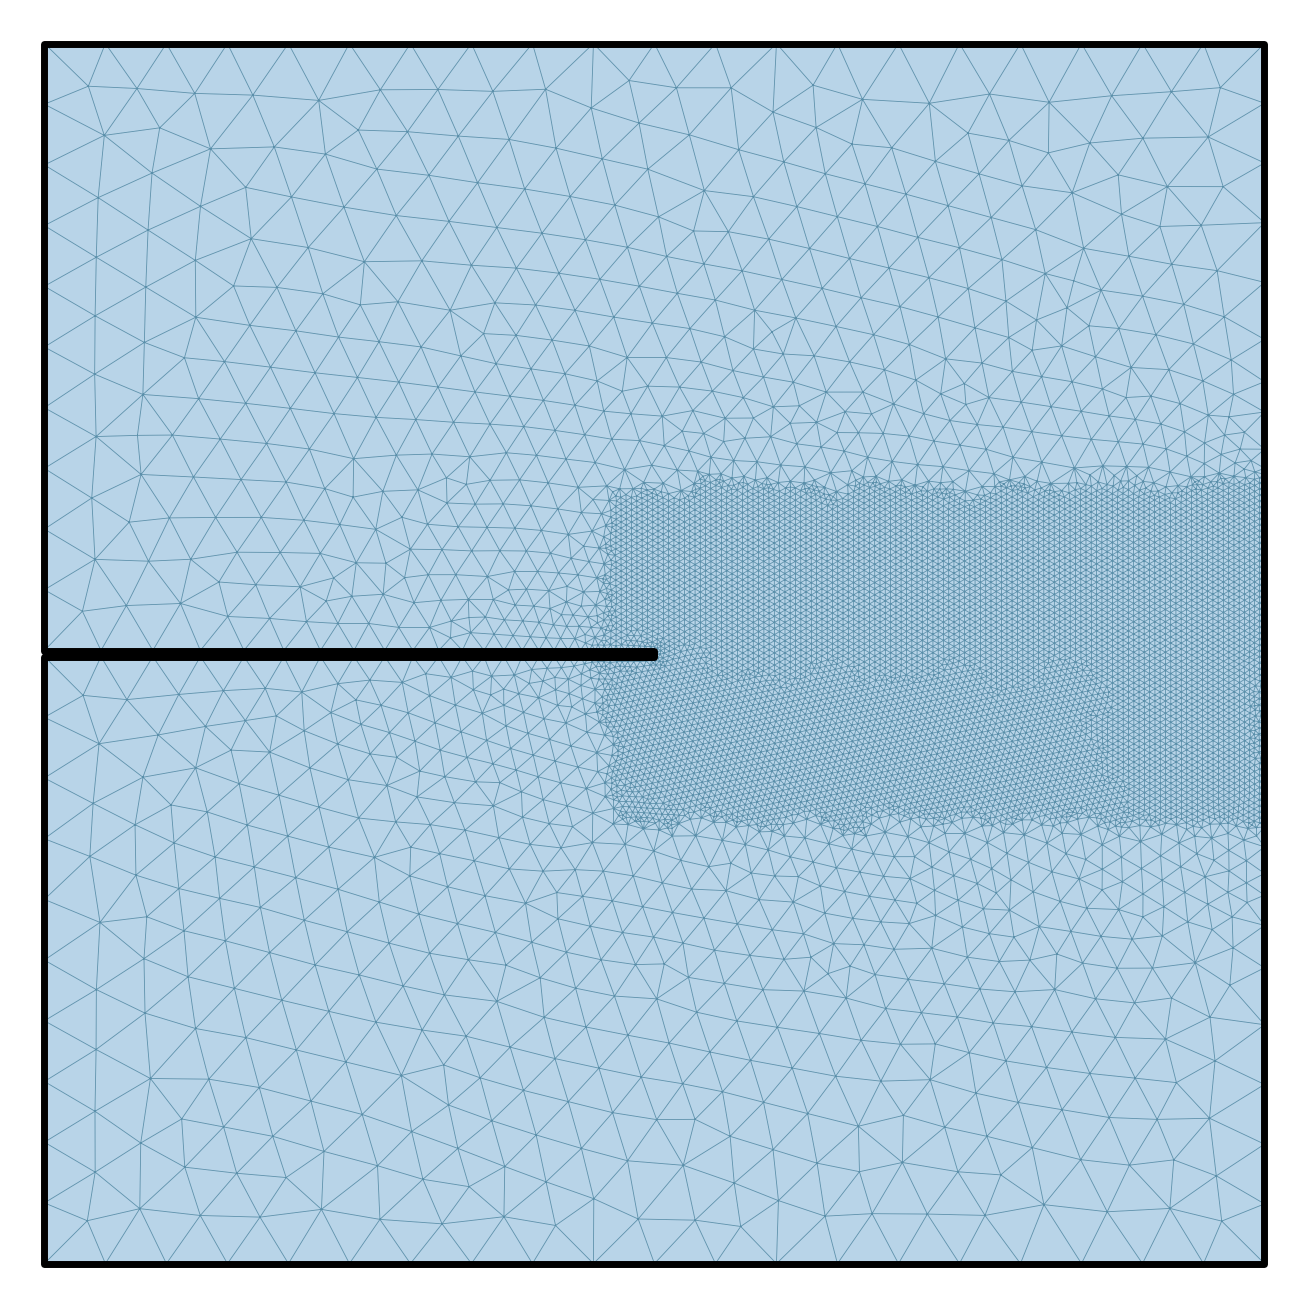

In [16]:
from pathlib import Path
from collections import defaultdict

import meshio
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.collections as mc
from scipy.spatial import cKDTree

msh_path = Path('/Users/zhangpeng/Desktop/PFM-paper/visualization/results_SENT_tension/mesh_SENT.msh')
mesh = meshio.read(msh_path)

coords = mesh.points[:, :2]
tris   = mesh.cells_dict['triangle']

# ── Merge duplicate nodes ──────────────────────────────────────────────────────
tree  = cKDTree(coords)
pairs = tree.query_pairs(r=1e-10)
parent = list(range(len(coords)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x

for a, b in pairs:
    ra, rb = find(a), find(b)
    if ra != rb: parent[ra] = rb

remap = np.array([find(i) for i in range(len(coords))])
unique_ids, inv = np.unique(remap, return_inverse=True)
merged_coords = coords[unique_ids]
merged_tris   = inv[tris].astype(int)

# ── Extract boundary loops ─────────────────────────────────────────────────────
edge_count = {}
for tri in merged_tris:
    for i in range(3):
        a, b = tri[i], tri[(i+1)%3]
        key = (min(a,b), max(a,b))
        edge_count[key] = edge_count.get(key, 0) + 1

bdy_edges = {e for e, cnt in edge_count.items() if cnt == 1}
adj = defaultdict(list)
for a, b in bdy_edges:
    adj[a].append(b); adj[b].append(a)

visited, loops = set(), []
for start in adj:
    if start in visited: continue
    chain = [start]; visited.add(start); cur = start
    while True:
        nxt = [n for n in adj[cur] if n not in visited]
        if not nxt: break
        nxt = nxt[0]; visited.add(nxt); chain.append(nxt); cur = nxt
    if len(chain) > 1:
        loops.append(np.array([merged_coords[n] for n in chain]))

def poly_area(pts):
    x, y = pts[:,0], pts[:,1]
    return 0.5 * abs(np.dot(x, np.roll(y,-1)) - np.dot(y, np.roll(x,-1)))

outer_idx = int(np.argmax([poly_area(lp) for lp in loops]))

# ── Plot ───────────────────────────────────────────────────────────────────────
xmin, ymin = coords.min(axis=0)
xmax, ymax = coords.max(axis=0)
padx = 0.02*(xmax-xmin);  pady = 0.02*(ymax-ymin)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
fig.patch.set_facecolor('white')   # outside boundary → white
ax.set_facecolor('white')

# Mesh interior filled with light blue
ax.add_collection(mc.PolyCollection(
    coords[tris], facecolor='#B8D4E8', edgecolor='none', zorder=1))

# Mesh lines
ax.triplot(coords[:,0], coords[:,1], tris,
           color='#5A8FAA', linewidth=0.3, zorder=2)

# Boundary loops
for i, loop in enumerate(loops):
    closed = np.vstack([loop, loop[0]])
    lw = 2.5 if i == outer_idx else 1.0
    ax.plot(closed[:,0], closed[:,1],
            color='black', linewidth=lw,
            solid_capstyle='round', solid_joinstyle='round', zorder=3)

ax.set_xlim(xmin-padx, xmax+padx)
ax.set_ylim(ymin-pady, ymax+pady)
ax.set_aspect('equal')
ax.axis('off')
plt.tight_layout(pad=0.2)
plt.show()

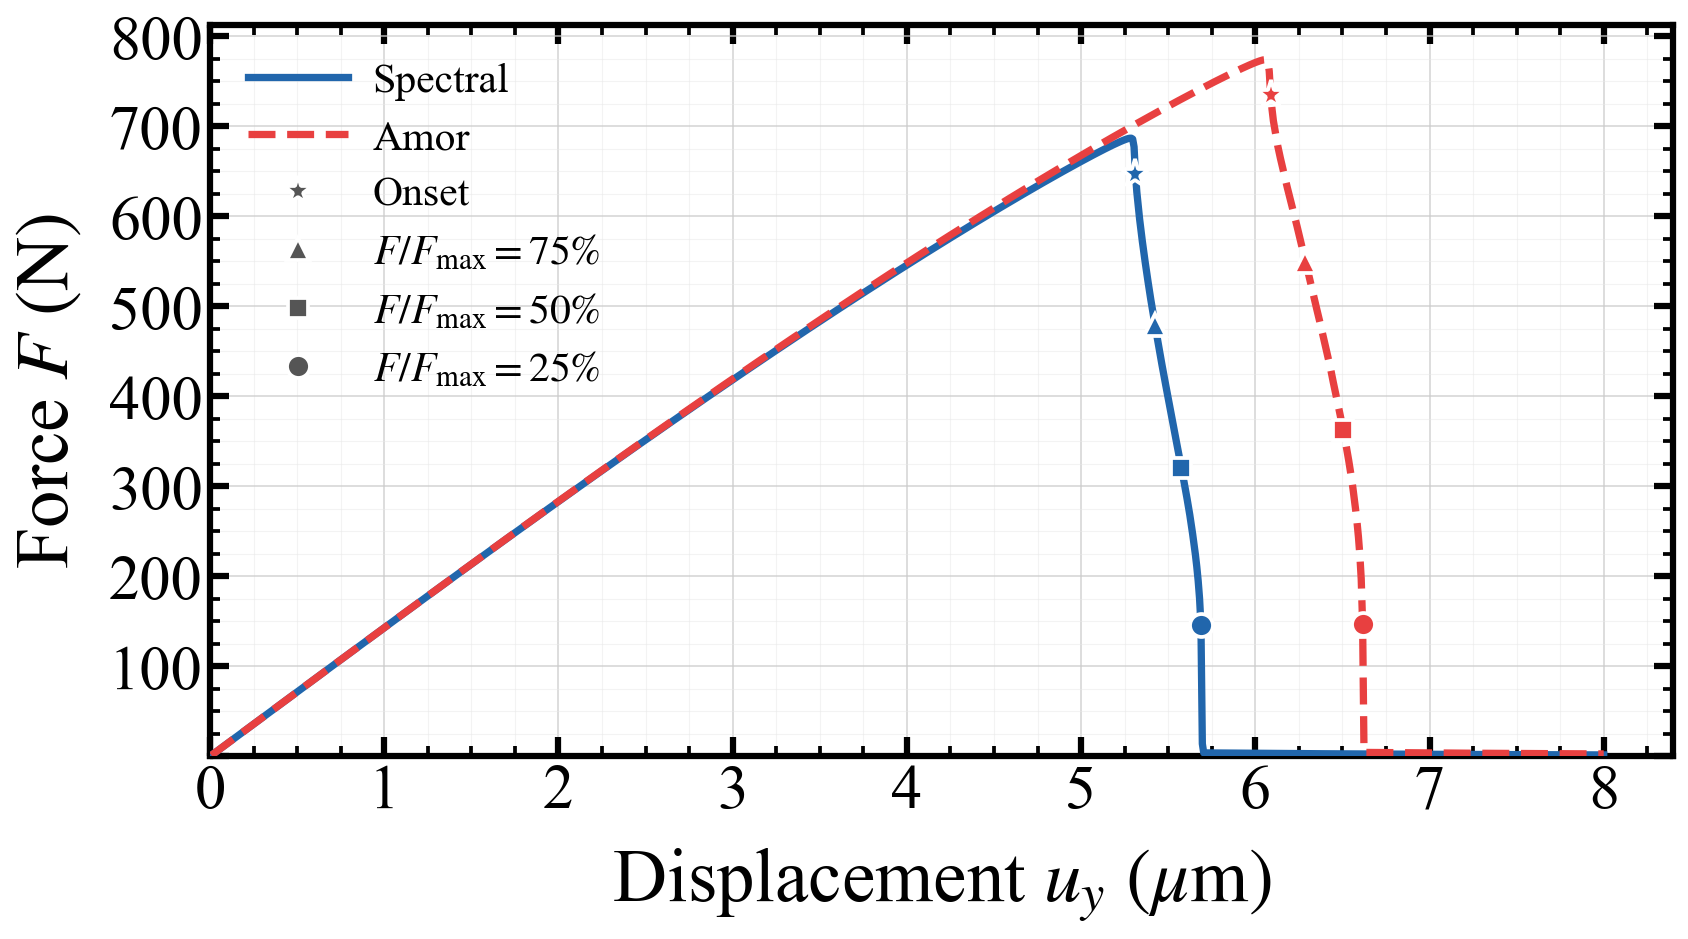

<Figure size 640x480 with 0 Axes>

In [2]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        34,
})

df = pd.read_csv('/Users/zhangpeng/Desktop/PFM-paper/visualization/results_SENT_tension/F_u_curve.csv')

u = df['u_mm'] * 1e3
F = df['F_N']

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from pathlib import Path

mpl.rcParams.update({
    'font.family':      'serif',
    'font.serif':       ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size':        34,
})

BASE = Path('/Users/zhangpeng/Desktop/PFM-paper/visualization/results_SENT_tension')

CURVES = [
    dict(fname='F_u_curve.csv',
         label='Spectral',
         color='#2166AC', ls='-',
         ms_steps=dict(onset=664, drop75=678, drop50=697, drop25=711)),
    dict(fname='F_u_curve_amor_eta0.csv',
         label='Amor',
         color='#E84040', ls='--',
         ms_steps=dict(onset=761, drop75=786, drop50=813, drop25=827)),
]

MS_STYLE = {
    'onset':  ('*', 14, r'Onset'),
    'drop75': ('^', 11, r'$F/F_{\max} = 75\%$'),
    'drop50': ('s', 10, r'$F/F_{\max} = 50\%$'),
    'drop25': ('o', 11, r'$F/F_{\max} = 25\%$'),
}

# ── load ──────────────────────────────────────────────────────────────────
for c in CURVES:
    df = pd.read_csv(BASE / c['fname'])
    c['u'] = df['u_mm'].values * 1e3
    c['F'] = df['F_N'].values
    c['ms'] = {}
    for name, step in c['ms_steps'].items():
        row = df[df['step'] == step]
        if not row.empty:
            c['ms'][name] = (row['u_mm'].values[0]*1e3, row['F_N'].values[0])

# ── figure ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 7), dpi=150)

ax.set_axisbelow(True)
ax.grid(True, which='major', color='#CCCCCC', linewidth=0.9, alpha=0.7)
ax.grid(True, which='minor', color='#E8E8E8', linewidth=0.5, alpha=0.5)

for c in CURVES:
    ax.plot(c['u'], c['F'],
            color=c['color'], linestyle=c['ls'],
            linewidth=3.5, zorder=4)

for c in CURVES:
    for name, (u_pt, F_pt) in c['ms'].items():
        mk, ms, _ = MS_STYLE[name]
        ax.plot(u_pt, F_pt,
                marker=mk, markersize=ms,
                color=c['color'],
                markeredgecolor='white', markeredgewidth=1.8,
                linestyle='none', zorder=6)

# ── axes styling ──────────────────────────────────────────────────────────
ax.set_xlabel(r'Displacement $u_y\ (\mu\mathrm{m})$', fontsize=36, labelpad=12)
ax.set_ylabel(r'Force $F\ (\mathrm{N})$',             fontsize=36, labelpad=12)

ax.tick_params(axis='both', which='major',
               labelsize=30, width=3.0, length=9, direction='in',
               top=True, right=True)
ax.tick_params(axis='both', which='minor',
               width=1.8, length=5, direction='in',
               top=True, right=True)
ax.xaxis.set_major_locator(ticker.MultipleLocator(1))
ax.yaxis.set_major_locator(ticker.MultipleLocator(100))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.25))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(25))
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, _: '' if x == 0 else f'{x:g}'))

for spine in ax.spines.values():
    spine.set_linewidth(3.0)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.margins(x=0.03, y=0.07)

# ── legend ────────────────────────────────────────────────────────────────
c_handles = [
    Line2D([0],[0], color=c['color'], linestyle=c['ls'],
           linewidth=3.5, label=c['label'])
    for c in CURVES
]
m_handles = [
    Line2D([0],[0], marker=mk, markersize=ms,
           color='#555555', markeredgecolor='white', markeredgewidth=1.8,
           linestyle='none', label=lbl)
    for mk, ms, lbl in MS_STYLE.values()
]
ax.legend(handles=c_handles + m_handles,
          fontsize=20, frameon=False,
          loc='upper left',
          handlelength=2.4, handletextpad=0.6,
          borderaxespad=0.5, labelspacing=0.45)

plt.tight_layout(pad=1.0)
plt.show()

ax.plot(u, F, color='#2166AC', linewidth=4.5, solid_capstyle='round')

for spine in ax.spines.values():
    spine.set_linewidth(4.0)

ax.grid(True, which='major', linestyle='--', linewidth=1.0,
        color='#AAAAAA', alpha=0.7)
ax.set_axisbelow(True)

ax.set_xlabel(r'Displacement $u_y\ (\mu\mathrm{m})$', fontsize=36, labelpad=12)
ax.set_ylabel(r'Force $F\ (\mathrm{N})$',             fontsize=36, labelpad=12)
ax.tick_params(axis='both', which='major',
               labelsize=32, width=3.5, length=8, direction='in',
               top=True, right=True)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.margins(x=0.04, y=0.06)

# 去掉 y 轴的 0 刻度标签
yticks = ax.get_yticks()
ax.set_yticks([t for t in yticks if t != 0])

plt.tight_layout(pad=1.2)
plt.show()